In [40]:
import warnings
warnings.filterwarnings('ignore')

In [1]:
import pandas as pd

In [6]:
column_names = [
    'age',
    'sex',
    'cp',
    'trestbps',
    'chol',
    'fbs',
    'restecg',
    'thalach',
    'exang',
    'oldpeak',
    'slope',
    'ca',
    'thal',
    'target'
]
heart = pd.read_csv(
    '../data/heart.csv',
    header=None,
    names=column_names
)

heart.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [7]:
heart.shape

(303, 14)

In [8]:
heart.columns.tolist()

['age',
 'sex',
 'cp',
 'trestbps',
 'chol',
 'fbs',
 'restecg',
 'thalach',
 'exang',
 'oldpeak',
 'slope',
 'ca',
 'thal',
 'target']

In [9]:
heart['target'].value_counts()

target
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

In [10]:
heart.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        303 non-null    object 
 12  thal      303 non-null    object 
 13  target    303 non-null    int64  
dtypes: float64(11), int64(1), object(2)
memory usage: 33.3+ KB


In [11]:
heart.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [12]:
heart.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,4.000000


In [14]:
heart['target'].value_counts().sort_index()

target
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

In [15]:
heart['ca'].value_counts(dropna=False)

ca
0.0    176
1.0     65
2.0     38
3.0     20
?        4
Name: count, dtype: int64

In [16]:
heart['thal'].value_counts(dropna=False)

thal
3.0    166
7.0    117
6.0     18
?        2
Name: count, dtype: int64

In [17]:
heart['ca'].unique()

array(['0.0', '3.0', '2.0', '1.0', '?'], dtype=object)

In [18]:
heart['thal'].unique()

array(['6.0', '3.0', '7.0', '?'], dtype=object)

In [19]:
import numpy as np

In [25]:
heart = heart.replace('?', np.nan)

In [26]:
heart.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

In [22]:
heart['ca'] = pd.to_numeric(heart['ca'])
heart['thal'] = pd.to_numeric(heart['thal'])

In [23]:
heart.dtypes

age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object

In [24]:
heart.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

In [27]:
heart.duplicated().sum()

np.int64(0)

In [28]:
for col in heart.columns:
    print(f'{col} : {heart[col].unique()}')

age : [63. 67. 37. 41. 56. 62. 57. 53. 44. 52. 48. 54. 49. 64. 58. 60. 50. 66.
 43. 40. 69. 59. 42. 55. 61. 65. 71. 51. 46. 45. 39. 68. 47. 34. 35. 29.
 70. 77. 38. 74. 76.]
sex : [1. 0.]
cp : [1. 4. 3. 2.]
trestbps : [145. 160. 120. 130. 140. 172. 150. 110. 132. 117. 135. 112. 105. 124.
 125. 142. 128. 170. 155. 104. 180. 138. 108. 134. 122. 115. 118. 100.
 200.  94. 165. 102. 152. 101. 126. 174. 148. 178. 158. 192. 129. 144.
 123. 136. 146. 106. 156. 154. 114. 164.]
chol : [233. 286. 229. 250. 204. 236. 268. 354. 254. 203. 192. 294. 256. 263.
 199. 168. 239. 275. 266. 211. 283. 284. 224. 206. 219. 340. 226. 247.
 167. 230. 335. 234. 177. 276. 353. 243. 225. 302. 212. 330. 175. 417.
 197. 198. 290. 253. 172. 273. 213. 305. 216. 304. 188. 282. 185. 232.
 326. 231. 269. 267. 248. 360. 258. 308. 245. 270. 208. 264. 321. 274.
 325. 235. 257. 164. 141. 252. 255. 201. 222. 260. 182. 303. 265. 309.
 307. 249. 186. 341. 183. 407. 217. 288. 220. 209. 227. 261. 174. 281.
 221. 205. 240. 289. 31

In [29]:
heart['target'] = (heart['target'] > 0).astype(int)

In [30]:
heart['target'].value_counts()

target
0    164
1    139
Name: count, dtype: int64

In [31]:
heart['target'].value_counts(normalize=True)*100

target
0    54.125413
1    45.874587
Name: proportion, dtype: float64

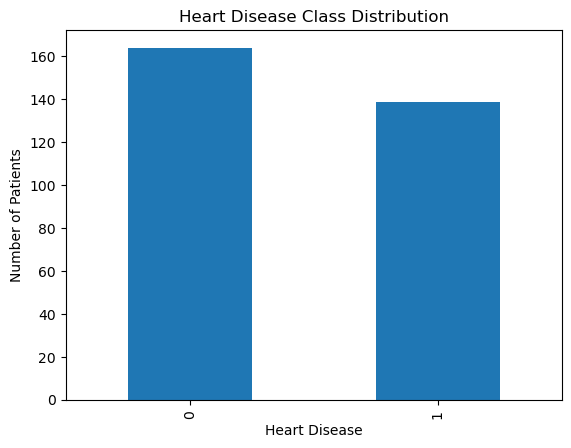

In [32]:
import matplotlib.pyplot as plt

heart['target'].value_counts().plot(kind = 'bar')
plt.xlabel('Heart Disease')
plt.ylabel('Number of Patients')
plt.title('Heart Disease Class Distribution')
plt.show()

In [33]:
heart.groupby('target')['age'].mean()

target
0    52.585366
1    56.625899
Name: age, dtype: float64

In [34]:
heart.groupby('target')['age'].median()

target
0    52.0
1    58.0
Name: age, dtype: float64

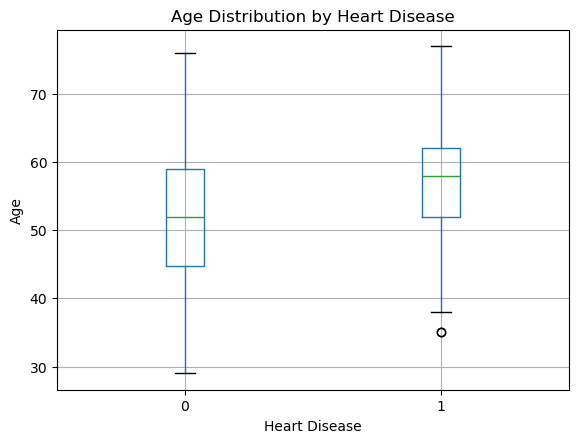

In [35]:
heart.boxplot(column = 'age', by = 'target')

plt.xlabel('Heart Disease')
plt.ylabel('Age')
plt.title('Age Distribution by Heart Disease')
plt.suptitle('')
plt.show()

In [36]:
pd.crosstab(heart['sex'], heart['target'])

target,0,1
sex,,
0.0,72,25
1.0,92,114


In [38]:
pd.crosstab(
    heart['sex'],
    heart['target'],
    normalize='index'
) * 100

target,0,1
sex,,
0.0,74.226804,25.773196
1.0,44.660194,55.339806


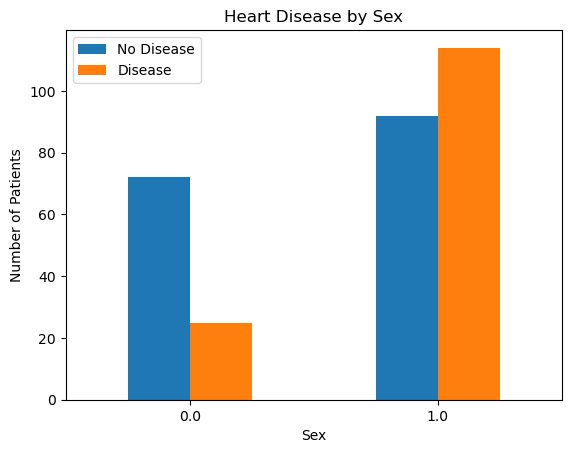

In [48]:
pd.crosstab(heart['sex'], heart['target']).plot(kind = 'bar')

plt.xlabel('Sex')
plt.ylabel('Number of Patients')
plt.title('Heart Disease by Sex')
plt.xticks(rotation = 0)
plt.legend(['No Disease', 'Disease'])
plt.show()

In [45]:
pd.crosstab(heart['cp'], heart['target'])

target,0,1
cp,,
1.0,16,7
2.0,41,9
3.0,68,18
4.0,39,105


In [46]:
pd.crosstab(
    heart['cp'],
    heart['target'],
    normalize='index'
) * 100

target,0,1
cp,,
1.0,69.565217,30.434783
2.0,82.000000,18.000000
3.0,79.069767,20.930233
4.0,27.083333,72.916667


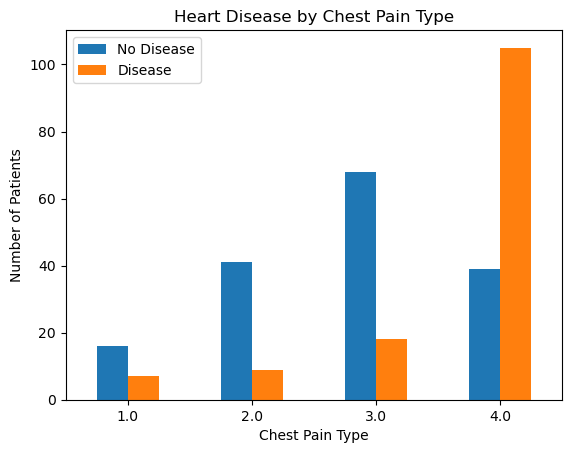

In [47]:
pd.crosstab(heart['cp'], heart['target']).plot(kind='bar')

plt.xlabel('Chest Pain Type')
plt.ylabel('Number of Patients')
plt.title('Heart Disease by Chest Pain Type')
plt.xticks(rotation=0)
plt.legend(['No Disease', 'Disease'])
plt.show()

In [49]:
heart.groupby('target')['thalach'].mean()

target
0    158.378049
1    139.258993
Name: thalach, dtype: float64

In [50]:
heart.groupby('target')['thalach'].median()

target
0    161.0
1    142.0
Name: thalach, dtype: float64

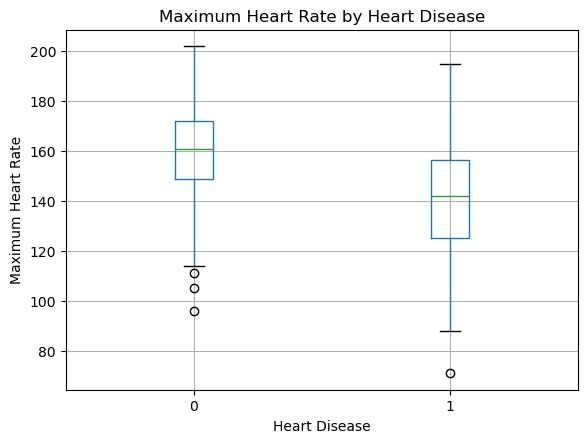

In [51]:
heart.boxplot(column='thalach', by='target')

plt.xlabel('Heart Disease')
plt.ylabel('Maximum Heart Rate')
plt.title('Maximum Heart Rate by Heart Disease')
plt.suptitle('')
plt.show()

In [52]:
heart.groupby('target')['chol'].mean()

target
0    242.640244
1    251.474820
Name: chol, dtype: float64

In [53]:
heart.groupby('target')['chol'].median()

target
0    234.5
1    249.0
Name: chol, dtype: float64

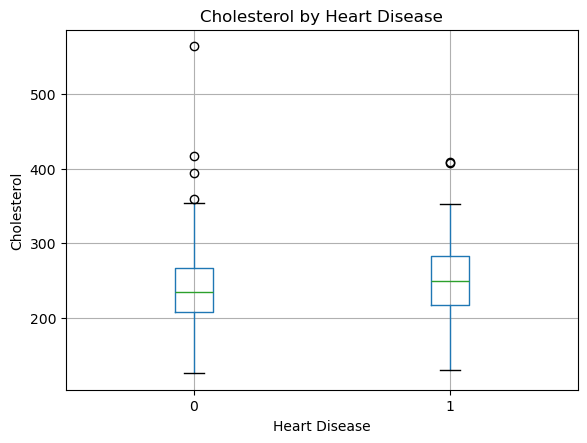

In [54]:
heart.boxplot(column='chol', by='target')

plt.xlabel('Heart Disease')
plt.ylabel('Cholesterol')
plt.title('Cholesterol by Heart Disease')
plt.suptitle('')
plt.show()

In [55]:
X = heart.drop('target', axis=1)
y = heart['target']

In [56]:
X.shape, y.shape

((303, 13), (303,))

In [57]:
from sklearn.model_selection import train_test_split

In [58]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [59]:
X_train.shape, X_test.shape

((242, 13), (61, 13))

In [60]:
y_train.value_counts()

target
0    131
1    111
Name: count, dtype: int64

In [61]:
numeric_features = [
    'age',
    'trestbps',
    'chol',
    'thalach',
    'oldpeak'
]

In [62]:
categorical_features = [
    'sex',
    'cp',
    'fbs',
    'restecg',
    'exang',
    'slope',
    'ca',
    'thal'
]

In [63]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [64]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [65]:
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [66]:
preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])

In [67]:
X_train_processed = preprocessor.fit_transform(X_train)

In [68]:
X_test_processed = preprocessor.transform(X_test)

In [69]:
X_train_processed.shape, X_test_processed.shape

((242, 28), (61, 28))

In [70]:
from sklearn.linear_model import LogisticRegression

In [71]:
logistic_model = LogisticRegression(max_iter=1000)

In [72]:
logistic_model.fit(X_train_processed, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [73]:
y_pred = logistic_model.predict(X_test_processed)

In [74]:
y_pred[:10]

array([0, 1, 0, 0, 0, 0, 0, 0, 1, 0])

In [75]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.8852459016393442


In [76]:
print("Accuracy:", accuracy * 100, "%")

Accuracy: 88.52459016393442 %


In [77]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [78]:
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))

Accuracy : 0.8852459016393442
Precision: 0.8387096774193549
Recall   : 0.9285714285714286
F1 Score : 0.8813559322033898


In [79]:
print(confusion_matrix(y_test, y_pred))

[[28  5]
 [ 2 26]]


In [80]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61



In [81]:
from sklearn.neighbors import KNeighborsClassifier

In [82]:
knn_model = KNeighborsClassifier(n_neighbors=5)

In [83]:
knn_model.fit(X_train_processed, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [84]:
knn_pred = knn_model.predict(X_test_processed)

In [85]:
print("Accuracy :", accuracy_score(y_test, knn_pred))
print("Precision:", precision_score(y_test, knn_pred))
print("Recall   :", recall_score(y_test, knn_pred))
print("F1 Score :", f1_score(y_test, knn_pred))

Accuracy : 0.8852459016393442
Precision: 0.8620689655172413
Recall   : 0.8928571428571429
F1 Score : 0.8771929824561403


In [86]:
print(confusion_matrix(y_test, knn_pred))

[[29  4]
 [ 3 25]]


In [87]:
from sklearn.naive_bayes import GaussianNB

In [88]:
naive_bayes_model = GaussianNB()

In [89]:
naive_bayes_model.fit(X_train_processed, y_train)

,priors,None
,var_smoothing,1e-09


In [90]:
nb_pred = naive_bayes_model.predict(X_test_processed)

In [91]:
print("Accuracy :", accuracy_score(y_test, nb_pred))
print("Precision:", precision_score(y_test, nb_pred))
print("Recall   :", recall_score(y_test, nb_pred))
print("F1 Score :", f1_score(y_test, nb_pred))

Accuracy : 0.7213114754098361
Precision: 0.6410256410256411
Recall   : 0.8928571428571429
F1 Score : 0.746268656716418


In [92]:
print(confusion_matrix(y_test, nb_pred))

[[19 14]
 [ 3 25]]


In [93]:
from sklearn.tree import DecisionTreeClassifier

In [94]:
decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

In [95]:
decision_tree_model.fit(X_train_processed, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [96]:
dt_pred = decision_tree_model.predict(X_test_processed)

In [97]:
print("Accuracy :", accuracy_score(y_test, dt_pred))
print("Precision:", precision_score(y_test, dt_pred))
print("Recall   :", recall_score(y_test, dt_pred))
print("F1 Score :", f1_score(y_test, dt_pred))

Accuracy : 0.7377049180327869
Precision: 0.6764705882352942
Recall   : 0.8214285714285714
F1 Score : 0.7419354838709677


In [98]:
print(confusion_matrix(y_test, dt_pred))

[[22 11]
 [ 5 23]]


In [99]:
from sklearn.ensemble import RandomForestClassifier

In [100]:
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [102]:
random_forest_model.fit(X_train_processed, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [103]:
rf_pred = random_forest_model.predict(X_test_processed)

In [104]:
print("Accuracy :", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall   :", recall_score(y_test, rf_pred))
print("F1 Score :", f1_score(y_test, rf_pred))

Accuracy : 0.8688524590163934
Precision: 0.8125
Recall   : 0.9285714285714286
F1 Score : 0.8666666666666667


In [105]:
print(confusion_matrix(y_test, rf_pred))

[[27  6]
 [ 2 26]]


In [106]:
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'KNN',
        'Naive Bayes',
        'Decision Tree',
        'Random Forest'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, knn_pred),
        accuracy_score(y_test, nb_pred),
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, rf_pred)
    ],
    'Precision': [
        precision_score(y_test, y_pred),
        precision_score(y_test, knn_pred),
        precision_score(y_test, nb_pred),
        precision_score(y_test, dt_pred),
        precision_score(y_test, rf_pred)
    ],
    'Recall': [
        recall_score(y_test, y_pred),
        recall_score(y_test, knn_pred),
        recall_score(y_test, nb_pred),
        recall_score(y_test, dt_pred),
        recall_score(y_test, rf_pred)
    ],
    'F1': [
        f1_score(y_test, y_pred),
        f1_score(y_test, knn_pred),
        f1_score(y_test, nb_pred),
        f1_score(y_test, dt_pred),
        f1_score(y_test, rf_pred)
    ]
})

In [107]:
results

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.885246,0.838710,0.928571,0.881356
1,KNN,0.885246,0.862069,0.892857,0.877193
2,Naive Bayes,0.721311,0.641026,0.892857,0.746269
3,Decision Tree,0.737705,0.676471,0.821429,0.741935
4,Random Forest,0.868852,0.812500,0.928571,0.866667


In [108]:
from sklearn.metrics import roc_auc_score

logistic_prob = logistic_model.predict_proba(X_test_processed)[:, 1]

logistic_auc = roc_auc_score(y_test, logistic_prob)

print("Logistic Regression ROC-AUC:", logistic_auc)

Logistic Regression ROC-AUC: 0.9664502164502166


In [109]:
rf_prob = random_forest_model.predict_proba(X_test_processed)[:, 1]

rf_auc = roc_auc_score(y_test, rf_prob)

print("Random Forest ROC-AUC:", rf_auc)

Random Forest ROC-AUC: 0.9426406926406926


In [111]:
final_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

In [112]:
final_pipeline.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [113]:
final_pred = final_pipeline.predict(X_test)

In [114]:
print("Accuracy :", accuracy_score(y_test, final_pred))
print("Precision:", precision_score(y_test, final_pred))
print("Recall   :", recall_score(y_test, final_pred))
print("F1 Score :", f1_score(y_test, final_pred))

Accuracy : 0.8852459016393442
Precision: 0.8387096774193549
Recall   : 0.9285714285714286
F1 Score : 0.8813559322033898


In [115]:
final_prob = final_pipeline.predict_proba(X_test)[:, 1]

print("ROC-AUC   :", roc_auc_score(y_test, final_prob))

ROC-AUC   : 0.9664502164502166


In [116]:
import joblib

In [117]:
joblib.dump(final_pipeline, '../ml/heart_model.pkl')

['../ml/heart_model.pkl']

In [118]:
import os

print(os.path.exists('../ml/heart_model.pkl'))

True
